## **Código para Modelagem 3D do Fóssil.**

Notebook que converte a saída do algoritmo de depth-from-focus (um mapa de "qual frame da pilha é mais nítido em cada pixel") em um modelo 3D colorido — nuvem de pontos e malha.

### **1. Contexto físico**
 
O módulo assume o rig de trilho vertical descrito no projeto:
 
- A câmera tem **foco fixo**. O plano de melhor foco fica sempre a
  `focus_distance_mm` **abaixo da câmera**.
- Quando a câmera está na altura `h(i)` (posição do frame `i` na pilha),
  o que estiver em foco naquele frame está fisicamente em:

      z = h(i) − focus_distance_mm

- Para `X` e `Y`, o módulo usa o modelo de câmera *pinhole* padrão,
  aproximando a distância câmera→ponto como `focus_distance_mm`
  (constante).

### **2. Fluxo de dados**
 
```
index_map (H,W)              metadata.csv / passo Z conhecido
        │                                    │
        ▼                                    ▼
      depth() ──────────► camera_height_mm[i] − focus_distance_mm
        │
        ▼
   Z_fóssil (H,W, mm)
        │
        ▼
pixels_to_xyz() ──► modelo pinhole ──► X, Y (mm) + Z (já calculado)
        │
        ▼
  vértices (N,3)
        │                     frame_000.png ... frame_NNN.png
        │                              │
        │                              ▼
        │                 load_image() + color_map()
        │                              │
        ▼                              ▼
  vértices (N,3)  +  cores RGB (N,3) do frame mais nítido de cada pixel
        │
        ▼
   build_grid()  (se malha; conecta vizinhos em triângulos)
        │
        ▼
     write_ply()  →  arquivo .ply (nuvem de pontos ou malha colorida)
```

In [32]:
# Bibliotecas.
from utils.functions import load_images, load_index_map
from dataclasses import dataclass
import matplotlib.pyplot as plt
from pathlib import Path
import pyvista as pv
import open3d as o3d
import numpy as np
import csv

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
# Parâmetros.
IMAGE_PATH = "../src/images/aligned/fossil"
ALTURA_MM = 246.9074
PASSO_MM = 2.23

In [3]:
# Download de Imagens
images = load_images(IMAGE_PATH)
N = len(images)


Fase 1.1: Ordenação.
Ordem de carregamento detectada: ['aligned_0000.jpg', 'aligned_0001.jpg', 'aligned_0002.jpg'] ...


In [8]:
# Carregamento do Mapa de Índices.
index_map = load_index_map("../results/depth/depth_map.npz")
display(index_map.shape)

(740, 1320)

In [9]:
# Filtro de Camada 0.
def filtrar(index_map: np.ndarray, radius: float, n: int, center: tuple[float, float] | None = None) -> np.ndarray:
    """Altera os pixels com valor 0 para -1 que estejam fora de um raio circular.

    Parameters
    ----------
    index_map : np.ndarray
        Matriz 2D contendo o mapa de índices.
    radius : float
        Raio do círculo (em pixels). O que estiver dentro do raio permanece inalterado.
    n : int
        Valor a ser atribuído aos pixels com valor 0 que estiverem fora do raio.
    center : tuple[float, float] | None, optional
        Coordenadas do centro do círculo. Se None, o centro será o centro da imagem.

    Returns
    -------
        Matriz filtrada (com dtype int32) onde pixels 0 fora do raio passam a ser n.

    """

    filter = index_map.copy()
    h, w = index_map.shape[:2]

    # Define o centro da imagem
    if center is None:
        cy, cx = h / 2.0 -100, w / 2.0 - 100 # ajuste para deslocar o centro da concha
    else:
        cy, cx = center

    # Gera grid de coordenadas (Y, X)
    y_grid, x_grid = np.ogrid[:h, :w]

    # Calcula a distância euclidiana de cada pixel em relação ao centro
    distances = np.sqrt((y_grid - cy) ** 2 + (x_grid - cx) ** 2)

    # Condição: estar fora do raio E ter valor igual a 0
    mask = (distances > radius) & (filter == 0)

    # Substitui por i[-1] apenas onde a condição é verdadeira
    filter[mask] = n

    return filter

In [ ]:
c = (index_map.shape[0] / 2.0 - 100, index_map.shape[1] / 2.0 - 100) # Desloca o centro manualmente.
index_map = filtrar(index_map, radius=200, center=c, n=N-1) # Aplica o filtro.

In [13]:
# plt.figure(figsize=(12, 6))
# plt.imshow(index_map, cmap='jet')
# plt.colorbar()
# plt.plot(index_map.shape[1]//2 -100, index_map.shape[0]//2 -100, 'ro')  # Marca o centro da imagem
# plt.title("Mapa de Índices")   
# plt.show()

### **3. Processamento dos Dados do Blender.**

Aplicando as funções para os parâmetros obtidos da simmulação do experimento com Blender.

In [14]:
@dataclass
class CameraParams:
    """Classe para armazenar os parâmetros da câmera."""
    focal_length_mm: float
    sensor_width_mm: float
    resolution: tuple
    sensor_height_mm: float = None

    def __post_init__(self):
        w_px, h_px = self.resolution
        if self.sensor_height_mm is None:
            self.sensor_height_mm = self.sensor_width_mm * (h_px / w_px)
        self.fx = self.focal_length_mm * w_px / self.sensor_width_mm    # px
        self.fy = self.focal_length_mm * h_px / self.sensor_height_mm  # px
        self.cx = w_px / 2.0
        self.cy = h_px / 2.0

In [15]:
# Extraindo Metadados da Imagem
def load_metadata(metadata_path: str):
    """Carrega os metadados da câmera a partir de um arquivo CSV."""

    rows = []
    with open(metadata_path, newline="") as f:
        reader = csv.DictReader(f)
        for row in reader:
            rows.append((int(row["frame"]), float(row["camera_height_mm"]),
                          float(row["focus_distance_mm"])))
    rows.sort(key=lambda r: r[0])
    camera_height_mm = np.array([r[1] for r in rows], dtype=np.float64)
    focus_distance_mm = rows[0][2]

    return camera_height_mm, focus_distance_mm

In [16]:
# Função para calcular a profundidade a partir do mapa de índices.
def depth(index_map, camera_height_mm, focus_distance_mm):
    """Calcula a profundidade a partir do mapa de índices.

    Parameters
    ----------
    index_map : np.ndarray
        Mapa de índices (2D).
    camera_height_mm : np.ndarray
        Altura da câmera em milímetros.
    focus_distance_mm : float
        Distância de foco em milímetros.
    passo_mm : float
        Passo entre as imagens em milímetros.

    Returns
    -------
    np.ndarray
        Mapa de profundidade (2D) em milímetros.
    """
    # Calcula a profundidade com base no índice e na altura da câmera
    depth_map = camera_height_mm[index_map] - focus_distance_mm
    return depth_map

In [17]:
# Cor: Pega o pixel do mapa de profundidade e retorna a cor correspondente no espectro de cores.
def color_map(images, index_map):
    """
    Para cada pixel, pega o RGB do frame mais nitido.
    """
    idx = np.rint(index_map).astype(int)
    idx = np.clip(idx, 0, images.shape[0] - 1)
    h, w = idx.shape
    ys, xs = np.meshgrid(np.arange(h), np.arange(w), indexing="ij")
    return images[idx, ys, xs, :]  # (H, W, 3) uint8

In [18]:
# Calcula as coordenadas 3D (X, Y, Z) a partir do mapa de profundidade.
def pixels_to_xyz(z_fossil_mm, camera, focus_distance_mm):
    """
    Converte coordenadas de pixel para coordenadas 3D (X, Y, Z) em milímetros.

    Parameters
    ----------
    z_fossil_mm : np.ndarray
        Mapa de profundidade (2D) em milímetros.
    camera : CameraParams
        Parâmetros da câmera.
    focus_distance_mm : float
        Distância de foco em milímetros.

    Returns
    -------
    np.ndarray
        Array 3D com coordenadas (X, Y, Z) em milímetros.
    """

    h, w = z_fossil_mm.shape
    us, vs = np.meshgrid(np.arange(w), np.arange(h))
 
    d = focus_distance_mm  # distancia camera->ponto 
    X = (us - camera.cx) * d / camera.fx
    Y = (vs - camera.cy) * d / camera.fy
    Z = z_fossil_mm
 
    return X, Y, Z

In [19]:
def build_grid(h, w, valid_mask=None):
    """Gera faces (triangulos) conectando pixels vizinhos de uma grade
    HxW. Se valid_mask for dado, pula quads com algum vertice invalido
    (ex: fundo, fora do fossil)."""
    faces = []
    for r in range(h - 1):
        for c in range(w - 1):
            if valid_mask is not None:
                quad = (valid_mask[r, c], valid_mask[r, c + 1],
                        valid_mask[r + 1, c], valid_mask[r + 1, c + 1])
                if not all(quad):
                    continue
            v00 = r * w + c
            v01 = r * w + (c + 1)
            v10 = (r + 1) * w + c
            v11 = (r + 1) * w + (c + 1)
            faces.append((v00, v10, v01))
            faces.append((v01, v10, v11))
    return faces

In [20]:
def write_ply(path, vertices, colors, faces=None):
    """vertices: (N,3) float; colors: (N,3) uint8; faces: lista de
    tuplas de 3 indices (opcional -- se None, escreve so nuvem de pontos)."""
    n_v = len(vertices)
    n_f = len(faces) if faces is not None else 0
 
    with open(path, "w") as f:
        f.write("ply\nformat ascii 1.0\n")
        f.write(f"element vertex {n_v}\n")
        f.write("property float x\nproperty float y\nproperty float z\n")
        f.write("property uchar red\nproperty uchar green\nproperty uchar blue\n")
        if faces is not None:
            f.write(f"element face {n_f}\n")
            f.write("property list uchar int vertex_indices\n")
        f.write("end_header\n")
 
        for (x, y, z), (r, g, b) in zip(vertices, colors):
            f.write(f"{x:.4f} {y:.4f} {z:.4f} {int(r)} {int(g)} {int(b)}\n")
 
        if faces is not None:
            for tri in faces:
                f.write(f"3 {tri[0]} {tri[1]} {tri[2]}\n")

In [22]:
# Cria uma máscara para os pixels válidos (não pertencentes ao fundo).
mask = ~((index_map == N-1))

In [25]:
# Pipeline
def reconstruct(best_index_map, camera_height_mm, focus_distance_mm, camera,
                 frames_dir, n_frames, output_ply,
                 as_mesh=True, mask=None, stride=1):
    """Monta a nuvem de pontos / malha 3D colorida e grava em output_ply.
 
    - best_index_map: (H,W) indice (int ou float) do frame mais nitido
      por pixel, na MESMA resolucao das imagens originais (antes de
      qualquer stride).
    - mask: (H,W) bool opcional -- True = pixel pertence ao fossil.
      Sem mascara, pixels de fundo (que nunca focam de verdade) entram
      como pontos espurios/ruidosos. Recomendado gerar essa mascara no
      seu codigo de focus-measure (ex: variancia maxima da pilha acima
      de um limiar).
    - stride: subamostra a grade (1 = resolucao total).
    """
    best_index_map = np.asarray(best_index_map)
    if stride > 1:
        best_index_map = best_index_map[::stride, ::stride]
        if mask is not None:
            mask = mask[::stride, ::stride]
 
    h, w = best_index_map.shape
 
    # 1) indice -> altura real (Z)
    z_fossil_mm = depth(best_index_map, camera_height_mm,
                                      focus_distance_mm)
 
    # 2) pixel -> XY no mundo (pinhole, d = distancia de foco fixa)
    X, Y, Z = pixels_to_xyz(z_fossil_mm, camera, focus_distance_mm)
 
    # 3) cor = pixel do frame mais nitido
    images = load_images(frames_dir)
    image_stack = np.stack(images, axis=0)
    colors = color_map(image_stack, best_index_map)
 
    vertices = np.stack([X, Y, Z], axis=-1).reshape(-1, 3)
    colors_flat = colors.reshape(-1, 3)
 
    if mask is None:
        faces = build_grid(h, w) if as_mesh else None
        write_ply(output_ply, vertices, colors_flat, faces)
    else:
        # com mascara: filtra pontos invalidos da nuvem, e (se malha)
        # gera faces so entre vizinhos validos e depois remapeia indices
        mask_flat = mask.reshape(-1)
        if as_mesh:
            faces = build_grid(h, w, valid_mask=mask)
            used = sorted(set(i for tri in faces for i in tri))
            remap = {old: new for new, old in enumerate(used)}
            faces = [(remap[a], remap[b], remap[c]) for a, b, c in faces]
            write_ply(output_ply, vertices[used], colors_flat[used], faces)
        else:
            write_ply(output_ply, vertices[mask_flat], colors_flat[mask_flat], None)
 
    print(f"[reconstruct] gravado em {output_ply} "
          f"({h}x{w} pixels, {'malha' if as_mesh else 'nuvem de pontos'})")

In [27]:
# Exemplo
if __name__ == "__main__":
    FRAMES_DIR = "../src/images/aligned/fossil"
    METADATA_CSV = "../src/metadata/metadata.csv"
    OUTPUT_PLY = "../results/3d/fossil.ply"
 
    camera_height_mm, focus_distance_mm = load_metadata(METADATA_CSV)
 
    cam = CameraParams(
        focal_length_mm=50.0,
        sensor_width_mm=36.0,
        resolution=(1920, 1080),
    )
 
    reconstruct(
        best_index_map=index_map,
        camera_height_mm=camera_height_mm,
        focus_distance_mm=focus_distance_mm,
        camera=cam,
        frames_dir=FRAMES_DIR,
        n_frames=len(camera_height_mm),
        output_ply=OUTPUT_PLY,
        as_mesh=True,
        mask=mask,
        stride=1,
    )
 


Fase 1.1: Ordenação.
Ordem de carregamento detectada: ['aligned_0000.jpg', 'aligned_0001.jpg', 'aligned_0002.jpg'] ...
[reconstruct] gravado em ../results/3d/fossil.ply (740x1320 pixels, malha)


In [29]:
def view(caminho_ply: str | Path):
    caminho = Path(caminho_ply)

    if not caminho.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {caminho}")

    # Carrega o arquivo PLY
    mesh = pv.read(caminho)

    # Configura o plotter
    plotter = pv.Plotter(window_size=[1024, 768])
    plotter.add_text(f"Fóssil: {caminho.name}", font_size=10)

    # Adiciona a geometria preservando as cores dos vértices (RGB)
    plotter.add_mesh(mesh, rgb=True, show_edges=False)
    plotter.add_axes()
    plotter.show_grid()

    # Exibe a janela
    plotter.show()

C:\Users\gusta\AppData\Local\Temp\ipykernel_23912\1842958820.py:20: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


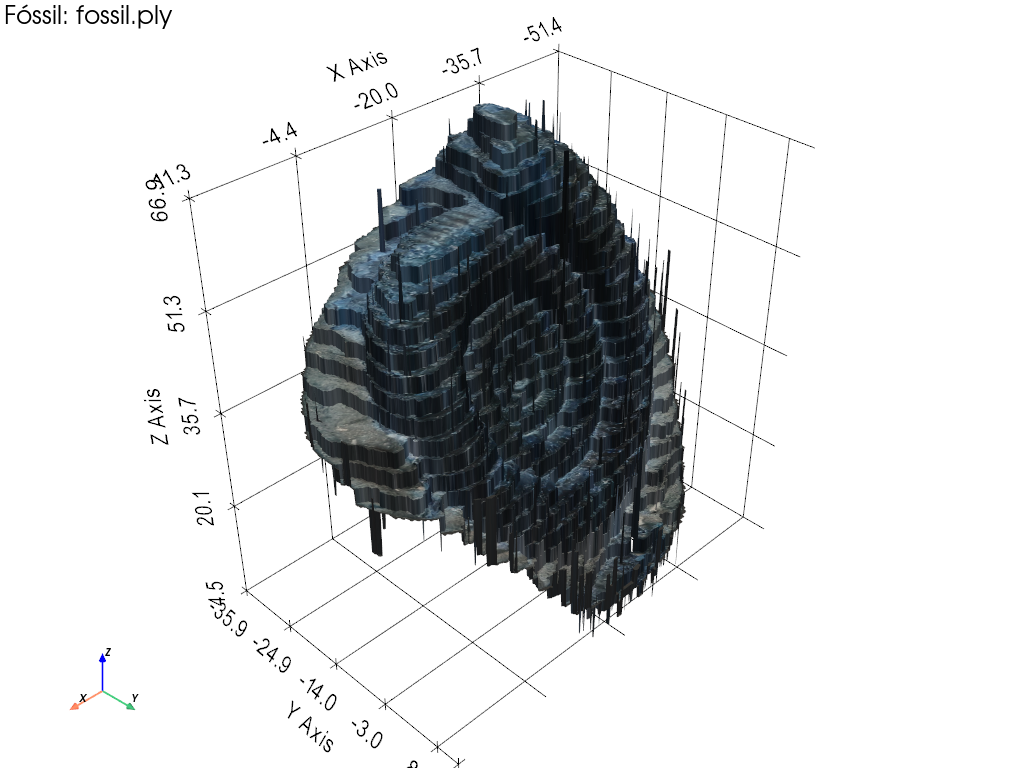

In [31]:
# Visualização do modelo 3D gerado.
view("../results/3d/fossil.ply")

In [33]:
def view_window(caminho_ply: str | Path):
    """Carrega o arquivo PLY gerado pelo pipeline e exibe na janela interativa."""
    caminho = Path(caminho_ply)

    if not caminho.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {caminho}")

    print(f"Carregando modelo de: {caminho}")
    mesh = o3d.io.read_triangle_mesh(str(caminho))

    if len(mesh.triangles) > 0:
        print(
            f"Exibindo Malha 3D ({len(mesh.vertices)} vértices, {len(mesh.triangles)} faces)"
        )
        # Recalcula normais.
        mesh.compute_vertex_normals()

        # Renderizar malha.
        o3d.visualization.draw_geometries(
            [mesh],
            window_name=f"Reconstrução 3D - {caminho.name}",
            width=1024,
            height=768,
            mesh_show_back_face=True,  # Nome correto do parâmetro
        )
    else:
        # Se não tiver faces (as_mesh=False), carrega como nuvem de pontos (PointCloud).
        pcd = o3d.io.read_point_cloud(str(caminho))
        print(f"Exibindo Nuvem de Pontos ({len(pcd.points)} pontos)")

        o3d.visualization.draw_geometries(
            [pcd],
            window_name=f"Reconstrução 3D - {caminho.name}",
            width=1024,
            height=768,
        )